
Assignment 3

Question1

In [1]:
import numpy as np

N = 10
e_min = -1
e_max = 1

# random vector in [e_min, e_max]
rand_vec = e_min + (e_max - e_min) * np.random.rand(N)

print(rand_vec)

[-0.88649597 -0.5897877   0.68688904 -0.8098133   0.45510637  0.59778339
  0.11298797  0.9146988  -0.97382947  0.22652763]


Question 2

In [2]:
import numpy as np

n = 4
e_min = 392
e_max = 505
rand_matrix = e_min + (e_max - e_min) * np.random.rand(n, n)
print(rand_matrix)

[[397.16452425 452.71579685 420.97528352 397.4344164 ]
 [460.62545084 413.26866598 500.93897948 439.97708149]
 [425.24501025 440.93011988 452.72044645 432.50648331]
 [434.03720086 471.03236589 406.18608151 403.16825637]]


Question 3

In [3]:
import numpy as np
from scipy import sparse

n = 4
density = 3 / 16
sparse_matrix = sparse.rand(n, n, density=density, format="csr", random_state=50)
print(sparse_matrix.toarray())
print(f"size of sparse matrix={sparse_matrix.shape}")
print(f"number of non-zero elements={sparse_matrix.nnz}")
print(f" sparsity of the sparse matrix={1-(sparse_matrix.nnz/(n*n)):.4f}")

[[0.         0.         0.         0.43930505]
 [0.         0.         0.         0.13478847]
 [0.         0.         0.         0.3251973 ]
 [0.         0.         0.         0.        ]]
size of sparse matrix=(4, 4)
number of non-zero elements=3
 sparsity of the sparse matrix=0.8125


Question 4

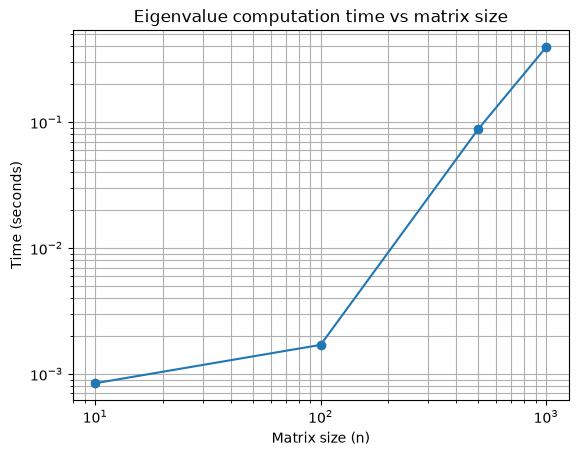

In [4]:
import numpy as np
import time
import matplotlib.pyplot as plt

# Different matrix sizes
n = [10, 100, 500, 1000]
elapsed_time = []

for ii in n:
    start_time = time.perf_counter()

    # random matrix
    rand_matrix = np.random.rand(ii, ii)

    # compute eigenvalues
    eigvals = np.linalg.eigvals(rand_matrix)

    end_time = time.perf_counter()

    elapsed_time.append(end_time - start_time)

# Plot in log-log scale
plt.figure()
plt.loglog(n, elapsed_time, marker='o')
plt.xlabel("Matrix size (n)")
plt.ylabel("Time (seconds)")
plt.title("Eigenvalue computation time vs matrix size")
plt.grid(True, which="both")
plt.show()

Question 5

[eigs] n=   10, time=0.0012 sec
[eigs] n=  100, time=0.0024 sec
[eigs] n=  500, time=0.0259 sec
[eigs] n= 1000, time=0.1152 sec
[eigs] n= 5000, time=3.8690 sec
[eigs] n=10000, time=8.1245 sec


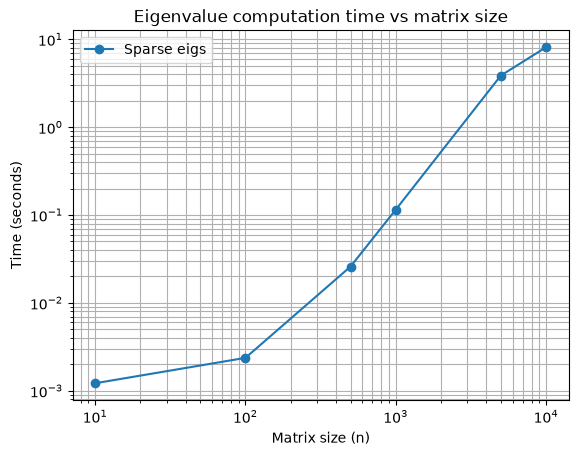

In [5]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigs

# Different matrix sizes
n_list = [10, 100, 500, 1000, 5000, 10000]

elapsed_time_sparse = []

# --- Sparse eigs timing ---
for n in n_list:
    start_time = time.perf_counter()

    density = 0.02
    sparse_matrix = sparse.rand(n, n, density=density, format="csr", random_state=50)

    A_sparse = sparse_matrix

    # compute 5 largest eigenvalues
    eigvals, eigvecs = eigs(A_sparse, k=5, which='LM')

    end_time = time.perf_counter()

    elapsed_time_sparse.append(end_time - start_time)
    print(f"[eigs] n={n:5d}, time={elapsed_time_sparse[-1]:.4f} sec")

# --- Plot ---
plt.figure()
plt.loglog(n_list, elapsed_time_sparse, marker='o', label="Sparse eigs")
plt.xlabel("Matrix size (n)")
plt.ylabel("Time (seconds)")
plt.title("Eigenvalue computation time vs matrix size")
plt.legend()
plt.grid(True, which="both")
plt.show()

Question 6

Matrix size n=1000, k=5, time=0.0143 sec
   Eigenvalue 1: -3.717740823223346
   Eigenvalue 2: -3.684455895123074
   Eigenvalue 3: 3.707072494979680
   Eigenvalue 4: 3.718334033324422
   Eigenvalue 5: 10.410999370969453

Matrix size n=1000, k=10, time=0.0241 sec
   Eigenvalue 1: -3.717740823223337
   Eigenvalue 2: -3.684455895123074
   Eigenvalue 3: -3.602027341348590
   Eigenvalue 4: -3.585945302905057
   Eigenvalue 5: 3.559985256767223

Matrix size n=1000, k=20, time=0.0273 sec
   Eigenvalue 1: -3.717740823223358
   Eigenvalue 2: -3.684455895123081
   Eigenvalue 3: -3.602027341348604
   Eigenvalue 4: -3.585945302905047
   Eigenvalue 5: -3.553807841762033

Matrix size n=1000, k=50, time=0.0510 sec
   Eigenvalue 1: -3.717740823223347
   Eigenvalue 2: -3.684455895123063
   Eigenvalue 3: -3.602027341348594
   Eigenvalue 4: -3.585945302905039
   Eigenvalue 5: -3.553807841762038

Matrix size n=1000, k=100, time=0.1773 sec
   Eigenvalue 1: -3.717740823223346
   Eigenvalue 2: -3.6844558951230

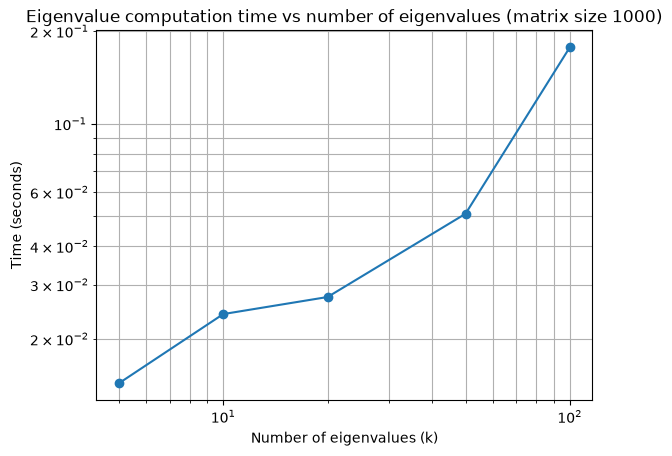

In [6]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigsh

# Matrix size
n = 1000
# Different numbers of eigenvalues to compute
nos_eigenvalues = [5, 10, 20, 50, 100]

elapsed_time = []

density = 2 / 100
sparse_matrix = sparse.rand(n, n, density=density, format="csr", random_state=50)
A_sparse = sparse_matrix
A_sparse = (A_sparse + A_sparse.T) / 2   # make it symmetric

for k in nos_eigenvalues:
    start_time = time.perf_counter()   # start timer

    # compute k eigenvalues
    eigvals, eigvecs = eigsh(A_sparse, k=k, which='LM')

    end_time = time.perf_counter()     # end timer

    elapsed_time.append(end_time - start_time)
    print(f"Matrix size n={n}, k={k}, time={elapsed_time[-1]:.4f} sec")
    # Print first 5 eigenvalues up to 15 decimal places
    for idx, val in enumerate(eigvals[:5]):
        print(f"   Eigenvalue {idx+1}: {val:.15f}")
    print()

# Plot in log-log scale
plt.figure()
plt.loglog(nos_eigenvalues, elapsed_time, marker='o')
plt.xlabel("Number of eigenvalues (k)")
plt.ylabel("Time (seconds)")
plt.title(f"Eigenvalue computation time vs number of eigenvalues (matrix size {n})")
plt.grid(True, which="both")
plt.show()

    Question 7

In [7]:
import numpy as np

# Minimum size (n) for 3 vectors to be linearly independent is n = 3
N = 3  # Number of vectors
n = 3  # Size of each vector (must be >= 3)

# Generate two random vectors of size N=3
v1 = np.random.rand(n)
v2 = np.random.rand(n)

# Generate a 3rd vector linearly dependent on v1 and v2
c1, c2 = 2, -1.5
v3 = c1 * v1 + c2 * v2

print("Vector 1 (v1):", v1)
print("Vector 2 (v2):", v2)
print("Vector 3 (v3 = 2*v1 - 1.5*v2):", v3)

Vector 1 (v1): [0.1141536  0.25691967 0.37527773]
Vector 2 (v2): [0.33822042 0.21437553 0.95677577]
Vector 3 (v3 = 2*v1 - 1.5*v2): [-0.27902342  0.19227606 -0.6846082 ]


In [8]:
import numpy as np

N = 4

# Generate the first vector using np.random.rand
v1 = np.random.rand(N)

# Generate the second vector using np.random.randn
v2 = np.random.randn(N)

# Generate two random scalar coefficients using np.random.rand
a = np.random.rand()
b = np.random.rand()

# Create a third vector that is a linear combination of the first two
v3 = a * v1 + b * v2

# Print the results
print("Using np.random.rand and np.random.randn:")
print(f"V1 : {v1}")
print(f"V2 : {v2}")
print(f" a: {a}")
print(f" b: {b}")
print(f"Linearly Dependent Vector 3 (a*v1 + b*v2): {v3}")

Using np.random.rand and np.random.randn:
V1 : [0.20002658 0.62412036 0.74917075 0.10684847]
V2 : [-1.15802953 -0.66096114 -0.59829311  0.63457959]
 a: 0.6448990613136272
 b: 0.9233991942854436
Linearly Dependent Vector 3 (a*v1 + b*v2): [-0.94032658 -0.20783635 -0.06932387  0.65487676]


Question 8

In [9]:
import numpy as np

N = 3
v1 = np.random.rand(N)
v2 = np.random.rand(N)
v3 = np.random.rand(N)
v4 = np.random.rand(N)
matrix = np.column_stack((v1, v2, v3, v4))
rank = np.linalg.matrix_rank(matrix)

print(f"Vector 1 (v1): {v1}")
print(f"Vector 2 (v2): {v2}")
print(f"Vector 3 (v3): {v3}")
print(f"Vector 4 (v4): {v4}")
print("\n--- Verification of Linear Independence ---")
print(f"The matrix formed by these four vectors is:\n{matrix}")
print(f"\nThe rank of this matrix is: {rank}")

if rank == 4:
    print("Since the rank of the matrix is 4, the vectors are linearly independent.")
else:
    print("The vectors are linearly dependent.")

Vector 1 (v1): [0.23314534 0.46049605 0.31221297]
Vector 2 (v2): [0.9339467  0.39964337 0.96643792]
Vector 3 (v3): [0.96063183 0.40599609 0.95890121]
Vector 4 (v4): [0.5778094  0.2711013  0.41032216]

--- Verification of Linear Independence ---
The matrix formed by these four vectors is:
[[0.23314534 0.9339467  0.96063183 0.5778094 ]
 [0.46049605 0.39964337 0.40599609 0.2711013 ]
 [0.31221297 0.96643792 0.95890121 0.41032216]]

The rank of this matrix is: 3
The vectors are linearly dependent.
